# 02 Random Forest baseline (Lab 6)

Pixel classifier. The bar the U-Net has to beat.

**Inputs**
- `data/raw/6950/naip/`
- `data/raw/6950/labels/`

**Output**
- `data/processed/6950_metrics_rf.json` (per-class IoU, mean IoU, confusion matrix)
- `docs/figures/02_rf_confusion.png`

Run `python musa6950/get_data.py` first. Use the geoai env.

In [1]:
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"
boxes = gpd.read_file(R6 / "sample_boxes.gpkg")
have = boxes.GEOID.map(lambda g: (R6 / "naip" / f"{g}.tif").exists() and (R6 / "labels" / f"{g}.tif").exists())
boxes = boxes[have].reset_index(drop=True)   # 4 boxes on the NY line have no 2022 PA image
boxes.groupby(["split", "stratum"]).size()

split  stratum 
test   rural        7
       suburban    10
       urban       10
train  rural       47
       suburban    49
       urban       50
dtype: int64

## Sample pixels

- Train boxes only
- 500 pixels per class per box
- Features: R, G, B, NIR, NDVI

In [2]:
CLASSES = ["other", "building", "tree", "open"]
rng = np.random.default_rng(42)


def features(img):
    """img (4, H, W) uint8 -> (H*W, 5) float32: R, G, B, NIR, NDVI."""
    x = img.reshape(4, -1).T.astype(np.float32)
    ndvi = (x[:, 3] - x[:, 0]) / (x[:, 3] + x[:, 0] + 1e-6)
    return np.column_stack([x / 255.0, ndvi])


def load(geoid):
    with rasterio.open(R6 / "naip" / f"{geoid}.tif") as s:
        img = s.read()
    with rasterio.open(R6 / "labels" / f"{geoid}.tif") as s:
        lab = s.read(1)
    return img, lab


Xs, ys = [], []
for g in boxes[boxes.split == "train"].GEOID:
    img, lab = load(g)
    f = features(img)
    l = lab.ravel()
    for c in range(4):
        idx = np.flatnonzero(l == c)
        if len(idx) == 0:
            continue
        take = rng.choice(idx, size=min(500, len(idx)), replace=False)
        Xs.append(f[take]); ys.append(l[take])
X = np.concatenate(Xs); y = np.concatenate(ys)
print(X.shape, np.bincount(y))

(290219, 5) [73000 71219 73000 73000]


## Train

- RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)

In [3]:
from sklearn.ensemble import RandomForestClassifier
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(X, y)
print(f"fit in {time.time() - t0:.0f} s")
print("feature importance:", dict(zip(["R", "G", "B", "NIR", "NDVI"], rf.feature_importances_.round(3))))

fit in 10 s


feature importance: {'R': 0.131, 'G': 0.192, 'B': 0.236, 'NIR': 0.166, 'NDVI': 0.275}


## Score on test counties

- Predict every pixel in the test boxes
- Confusion matrix, IoU per class, mean IoU
- Skip pixels labeled 255

In [4]:
def scores(cm):
    """cm[true, pred] -> per-class IoU, mIoU, overall accuracy."""
    tp = np.diag(cm).astype(float)
    iou = tp / (cm.sum(0) + cm.sum(1) - tp)
    return {"iou": dict(zip(CLASSES, iou.round(4).tolist())), "miou": round(float(iou.mean()), 4),
            "accuracy": round(float(tp.sum() / cm.sum()), 4)}


test = boxes[boxes.split == "test"]
cm = np.zeros((4, 4), dtype=np.int64)
cm_by = {s: np.zeros((4, 4), dtype=np.int64) for s in ["urban", "suburban", "rural"]}
rf_pred = {}
t0 = time.time()
for _, b in test.iterrows():
    img, lab = load(b.GEOID)
    l = lab.ravel()
    ok = l != 255
    pred = rf.predict(features(img)[ok])
    c = np.bincount(l[ok].astype(np.int64) * 4 + pred, minlength=16).reshape(4, 4)
    cm += c; cm_by[b.stratum] += c
    full = np.full(l.shape, 255, np.uint8); full[ok] = pred
    rf_pred[b.GEOID] = full.reshape(lab.shape)   # kept for the side-by-side figure in notebook 03
print(f"predicted {cm.sum():,} test pixels in {time.time() - t0:.0f} s")
np.savez_compressed(OUT / "6950_rf_test_pred.npz", **rf_pred)

res = scores(cm)
res["by_group"] = {s: scores(m) for s, m in cm_by.items()}
res["confusion"] = cm.tolist()
res["n_train_pixels"] = int(len(y)); res["n_test_pixels"] = int(cm.sum())
res["test_boxes"] = int(len(test))
print(json.dumps({k: res[k] for k in ["iou", "miou", "accuracy"]}, indent=1))
print(pd.DataFrame({s: v["iou"] | {"mIoU": v["miou"]} for s, v in res["by_group"].items()}))
(OUT / "6950_metrics_rf.json").write_text(json.dumps(res, indent=1))

predicted 109,183,195 test pixels in 1018 s


{
 "iou": {
  "other": 0.3211,
  "building": 0.2666,
  "tree": 0.3679,
  "open": 0.4853
 },
 "miou": 0.3602,
 "accuracy": 0.5711
}


           urban  suburban   rural
other     0.3411    0.2569  0.3446
building  0.2828    0.2248  0.2610
tree      0.3040    0.4150  0.3930
open      0.3594    0.5350  0.5547
mIoU      0.3218    0.3579  0.3883


948

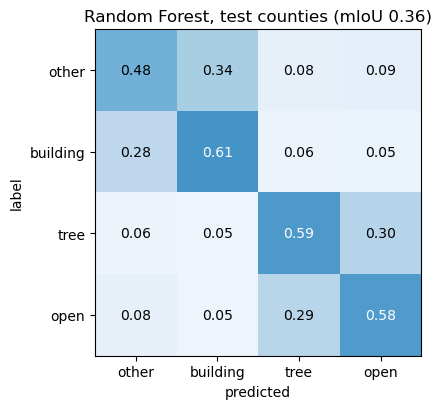

In [5]:
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(4), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("label")
ax.set_title(f"Random Forest, test counties (mIoU {res['miou']:.2f})")
plt.tight_layout()
plt.savefig(FIG / "02_rf_confusion.png", dpi=110)
plt.show()